# Introduction to PyTorch
It is a open source python-based DL library which is quite flexible and user-friendly.

## The three core components of PyTorch
1. Tensor library: a fundamental building block for efficient computing with the option to use GPUs for faster computations
2. Automatic differentiation engine or Autograd: utilities to automatically compute gradients for tensor operations, simplifying backpropagation and model optimization
3. DL library: utility functions that make it easier to implement and train deep neural networks.

## What is deep learning
- AI is concerned with creating computer systems that can perform tasks that require human intelligence. 
- ML is a sub-field of AI that focuses on developing algorithms by which the a machine can learn. The idea behind this is to allow machines to learn from available data, make predictions or decisions without being told to do so.
- DL is a sub-field of ML which focuses on learning algorithms inspired by the human brain (using deep "neural" networks). The "deep" here means the use of many hidden layers of neurons that allow the model to learn complex and non-linear relationships. 
- Typical supervised-learning setup looks like the following picture: 

![alt text](image.png)

## PyTorch
Pytorch has the capability to use GPUs for accelerated computing by utilizing parallelism. Depending on the machine and OS, we can have different options. For Mac machines like mine, we can use the MPS. Alternatively, if a GPU isn't present, one can use various cloud platforms that provide free but limited GPU compute.

## Understanding Tensors
Tensors are a generalization of vectors/matrices to higher dimensions. They can be characterized by their order (or rank), which gives the number of dimensions. Tensors serve as the containers that hold multidimensional data.

In [2]:
# Creating tensors

import torch

tensor0d = torch.tensor(1)
tensor1d = torch.tensor([1,2,3])
tensor2d = torch.tensor([[1,2], [3,4]])
tensor3d = torch.tensor([[[1,2],[3,4]], [[5,6], [7,8]]])

print("\n",tensor0d, "\n", tensor1d, "\n", tensor2d, "\n", tensor3d)


 tensor(1) 
 tensor([1, 2, 3]) 
 tensor([[1, 2],
        [3, 4]]) 
 tensor([[[1, 2],
         [3, 4]],

        [[5, 6],
         [7, 8]]])


In [3]:
# Checking and modifying a tensor's data type
print(tensor1d.dtype)
tensor1d = tensor1d.to(torch.float64)
print(tensor1d.dtype)

torch.int64
torch.float64


In [4]:
# Shape and reshaping of a tensor
print(tensor2d.shape)
tensor2d = tensor2d.reshape(4,1)
print(tensor2d.view(1,4))
print(tensor2d.shape)

torch.Size([2, 2])
tensor([[1, 2, 3, 4]])
torch.Size([4, 1])


In [5]:
# Transposing a tensor
print(tensor2d.shape)
print(tensor2d.T)

torch.Size([4, 1])
tensor([[1, 2, 3, 4]])


In [6]:
# Multiplying two matrices
print(tensor2d.matmul(tensor2d.T))
print(tensor2d @ tensor2d.T)


tensor([[ 1,  2,  3,  4],
        [ 2,  4,  6,  8],
        [ 3,  6,  9, 12],
        [ 4,  8, 12, 16]])
tensor([[ 1,  2,  3,  4],
        [ 2,  4,  6,  8],
        [ 3,  6,  9, 12],
        [ 4,  8, 12, 16]])


## Models as computation graphs
A computational graph is a visualization that helps us understand the mathematical expressions. In DL it shows the sequence of operations needed to compute the output of a neural network.

In [7]:
# A logistic regression forward pass
import torch.nn.functional as F

y = torch.tensor([1.0]) # true label
x1 = torch.tensor([1.1]) # input feature
w1 = torch.tensor([2.2]) # weight parameter
b = torch.tensor([0.0]) # bias
z = x1 * w1 + b # net input
a = torch.sigmoid(z) # activation
loss = F.binary_cross_entropy(a,y) # output
print(loss)

tensor(0.0852)


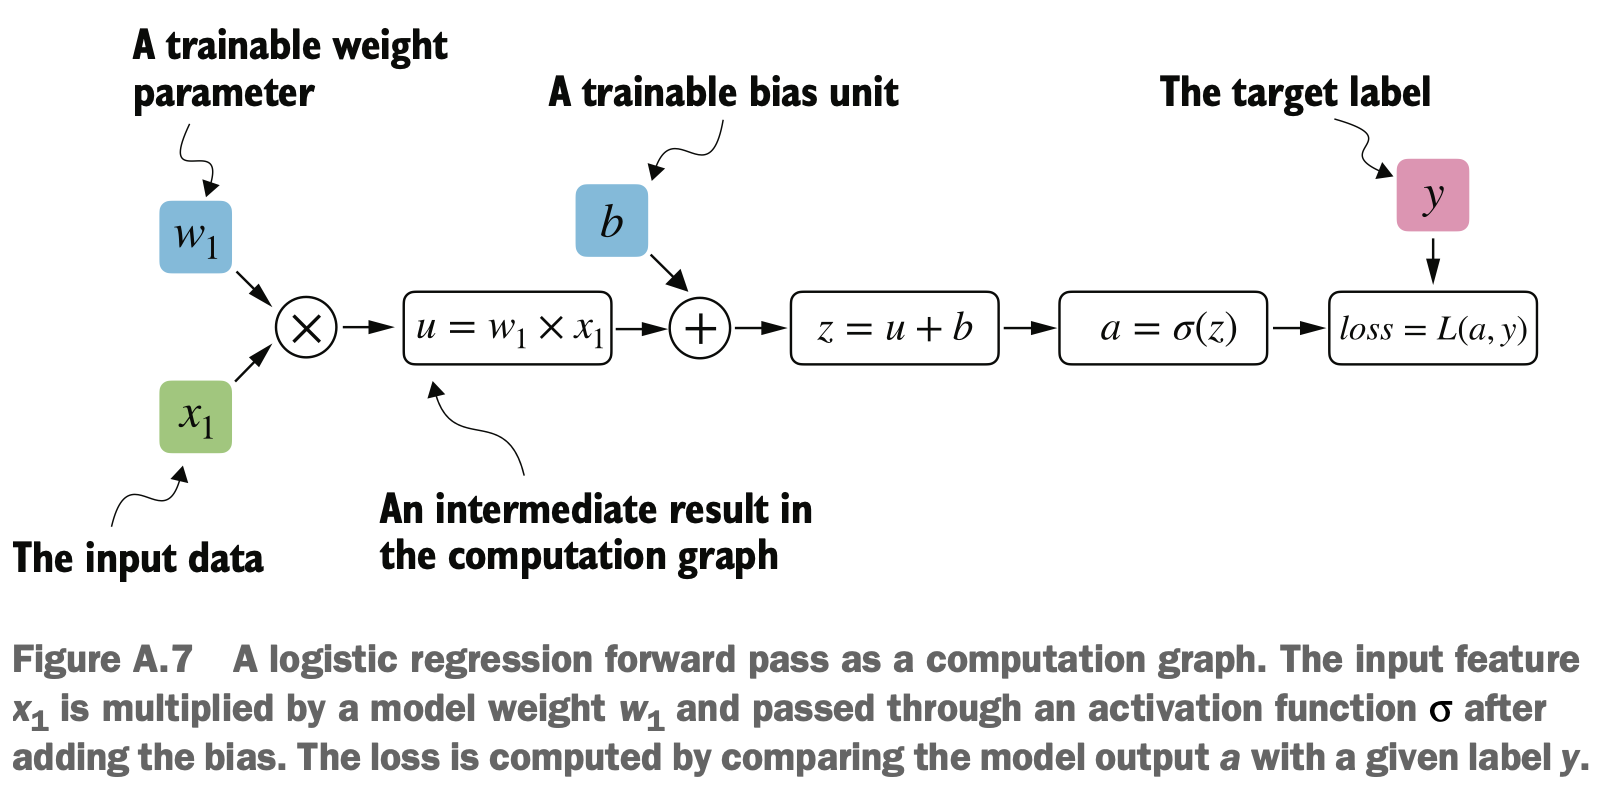

Pytorch builds a similar graph to calculate gradients of the loss function with respect to the model parameters.

## Automatic differentiation
Pytorch uses computational graphs to calculate the gradients which are later used in backpropagation to train the network.

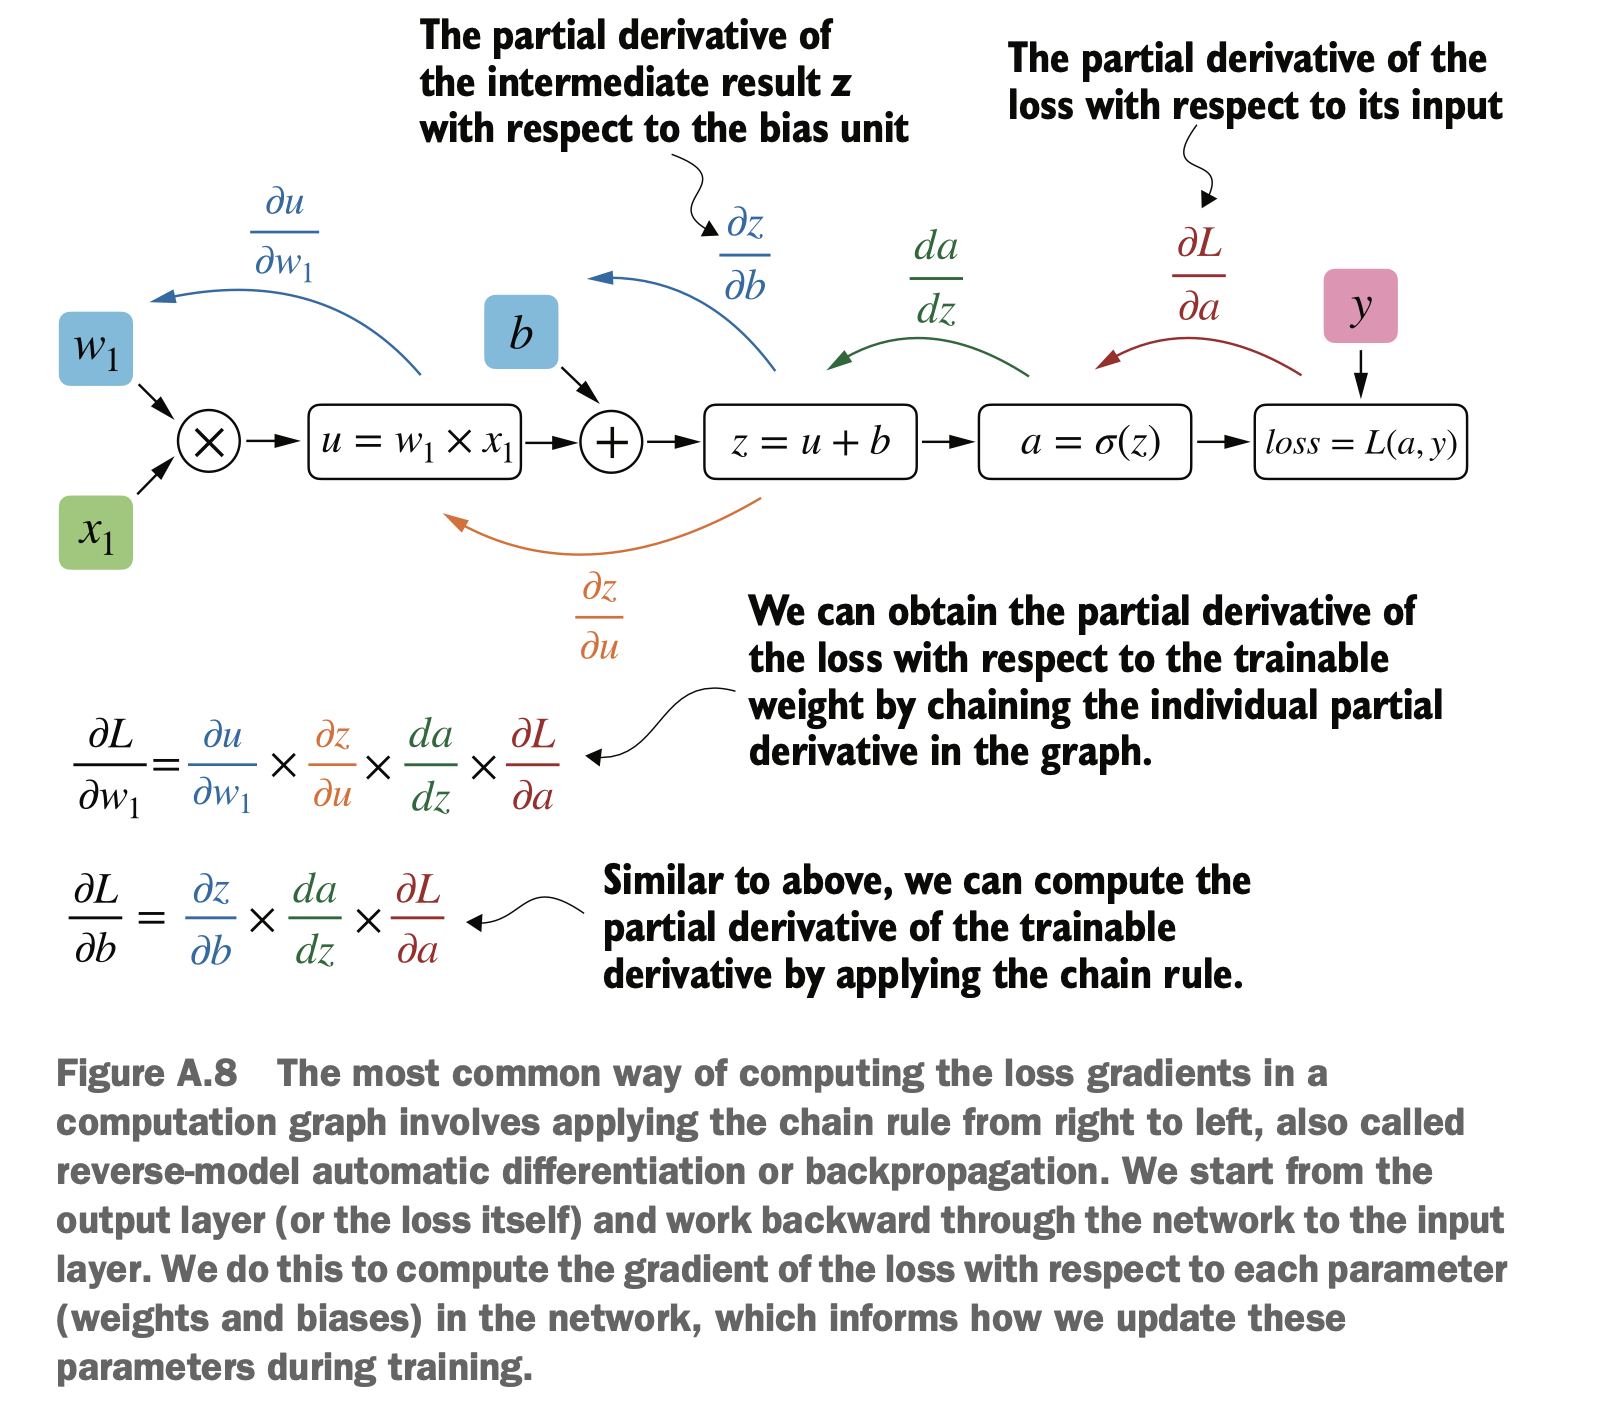

A gradient is a vector containing all the partial derivatives of a multivariate function.

In [8]:
import torch.nn.functional as F
from torch.autograd import grad

y = torch.tensor([1.0]) # true label
x1 = torch.tensor([1.1]) # input feature
w1 = torch.tensor([2.2], requires_grad=True) # weight parameter
b = torch.tensor([0.0], requires_grad=True) # bias

z = x1 * w1 + b # net input
a = torch.sigmoid(z) # activation

loss = F.binary_cross_entropy(a,y) # output

grad_L_w1 = grad(loss, w1, retain_graph=True)
grad_L_b = grad(loss, b, retain_graph=True)
# by default, Pytorch destroys the computation graph after calculating the gradients, but we want to use them later as well, so we keep them in the memory.
print(grad_L_w1)
print(grad_L_b)

(tensor([-0.0898]),)
(tensor([-0.0817]),)


In the last example we use the grad function manually, but Pytorch provides more high-level tools to automate it. We can call ```.backwards``` on the loss and Pytorch will store the gradients via the tensors' ```.grad``` attribute.

In [9]:
import torch.nn.functional as F
from torch.autograd import grad

y = torch.tensor([1.0]) # true label
x1 = torch.tensor([1.1]) # input feature
w1 = torch.tensor([2.2], requires_grad=True) # weight parameter
b = torch.tensor([0.0], requires_grad=True) # bias

z = x1 * w1 + b # net input
a = torch.sigmoid(z) # activation

loss = F.binary_cross_entropy(a,y) # output

loss.backward()

print(w1.grad)
print(b.grad)

tensor([-0.0898])
tensor([-0.0817])


## Implementing a MLP (Multilayer Perceptron)
It is a fully connected neural network.

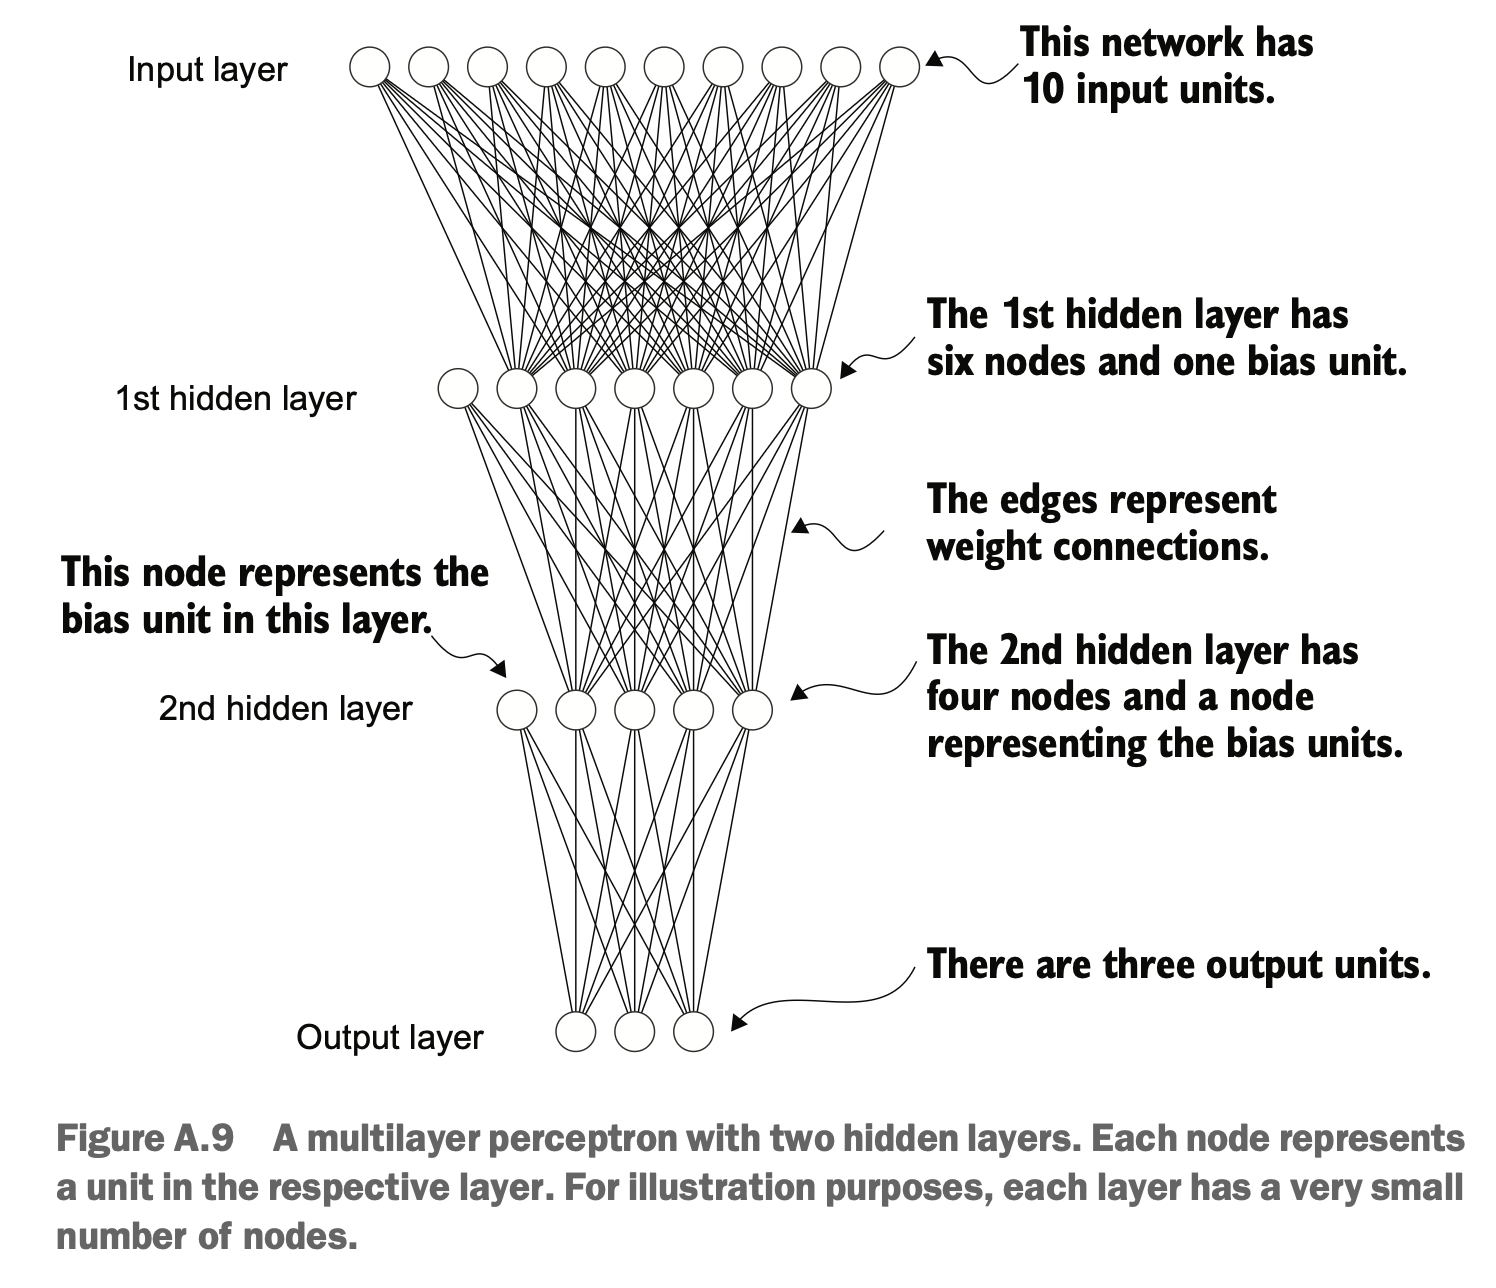

The ```torch.nn.Module``` class provides a lot of functionalities that makes building and training custom models relatively easy.

In [10]:
# A MLP with two hidden layers
class NeuralNetwork(torch.nn.Module):
    def __init__(self, num_inputs, num_outputs): # using variable ip/op helps in using the same code for various datasets
        super().__init__()
        self.layers = torch.nn.Sequential(
            torch.nn.Linear(num_inputs, 30), # number of inputs and output as arguments
            torch.nn.ReLU(), # non-linear activation
            torch.nn.Linear(30, 20), # input must match to the output of previous layer and output with the input of next layer
            torch.nn.ReLU(),
            torch.nn.Linear(20, num_outputs),
        )

    def forward(self, x):
        logits = self.layers(x)
        return logits

model = NeuralNetwork(50, 3)

print(model)

num_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print("Total number of trainable model parameters: ", num_params)

print(model.layers[0].weight.shape)

NeuralNetwork(
  (layers): Sequential(
    (0): Linear(in_features=50, out_features=30, bias=True)
    (1): ReLU()
    (2): Linear(in_features=30, out_features=20, bias=True)
    (3): ReLU()
    (4): Linear(in_features=20, out_features=3, bias=True)
  )
)
Total number of trainable model parameters:  2213
torch.Size([30, 50])


In [11]:
# forward pass
torch.manual_seed(123)
X = torch.rand((1,50))
out = model(X)
print(out)

tensor([[ 0.0190,  0.1817, -0.1817]], grad_fn=<AddmmBackward0>)


## Setting up efficient data loaders
Dataloaders are needed to efficiently supply data while training and testing. the idea is demonstrated in the following image.

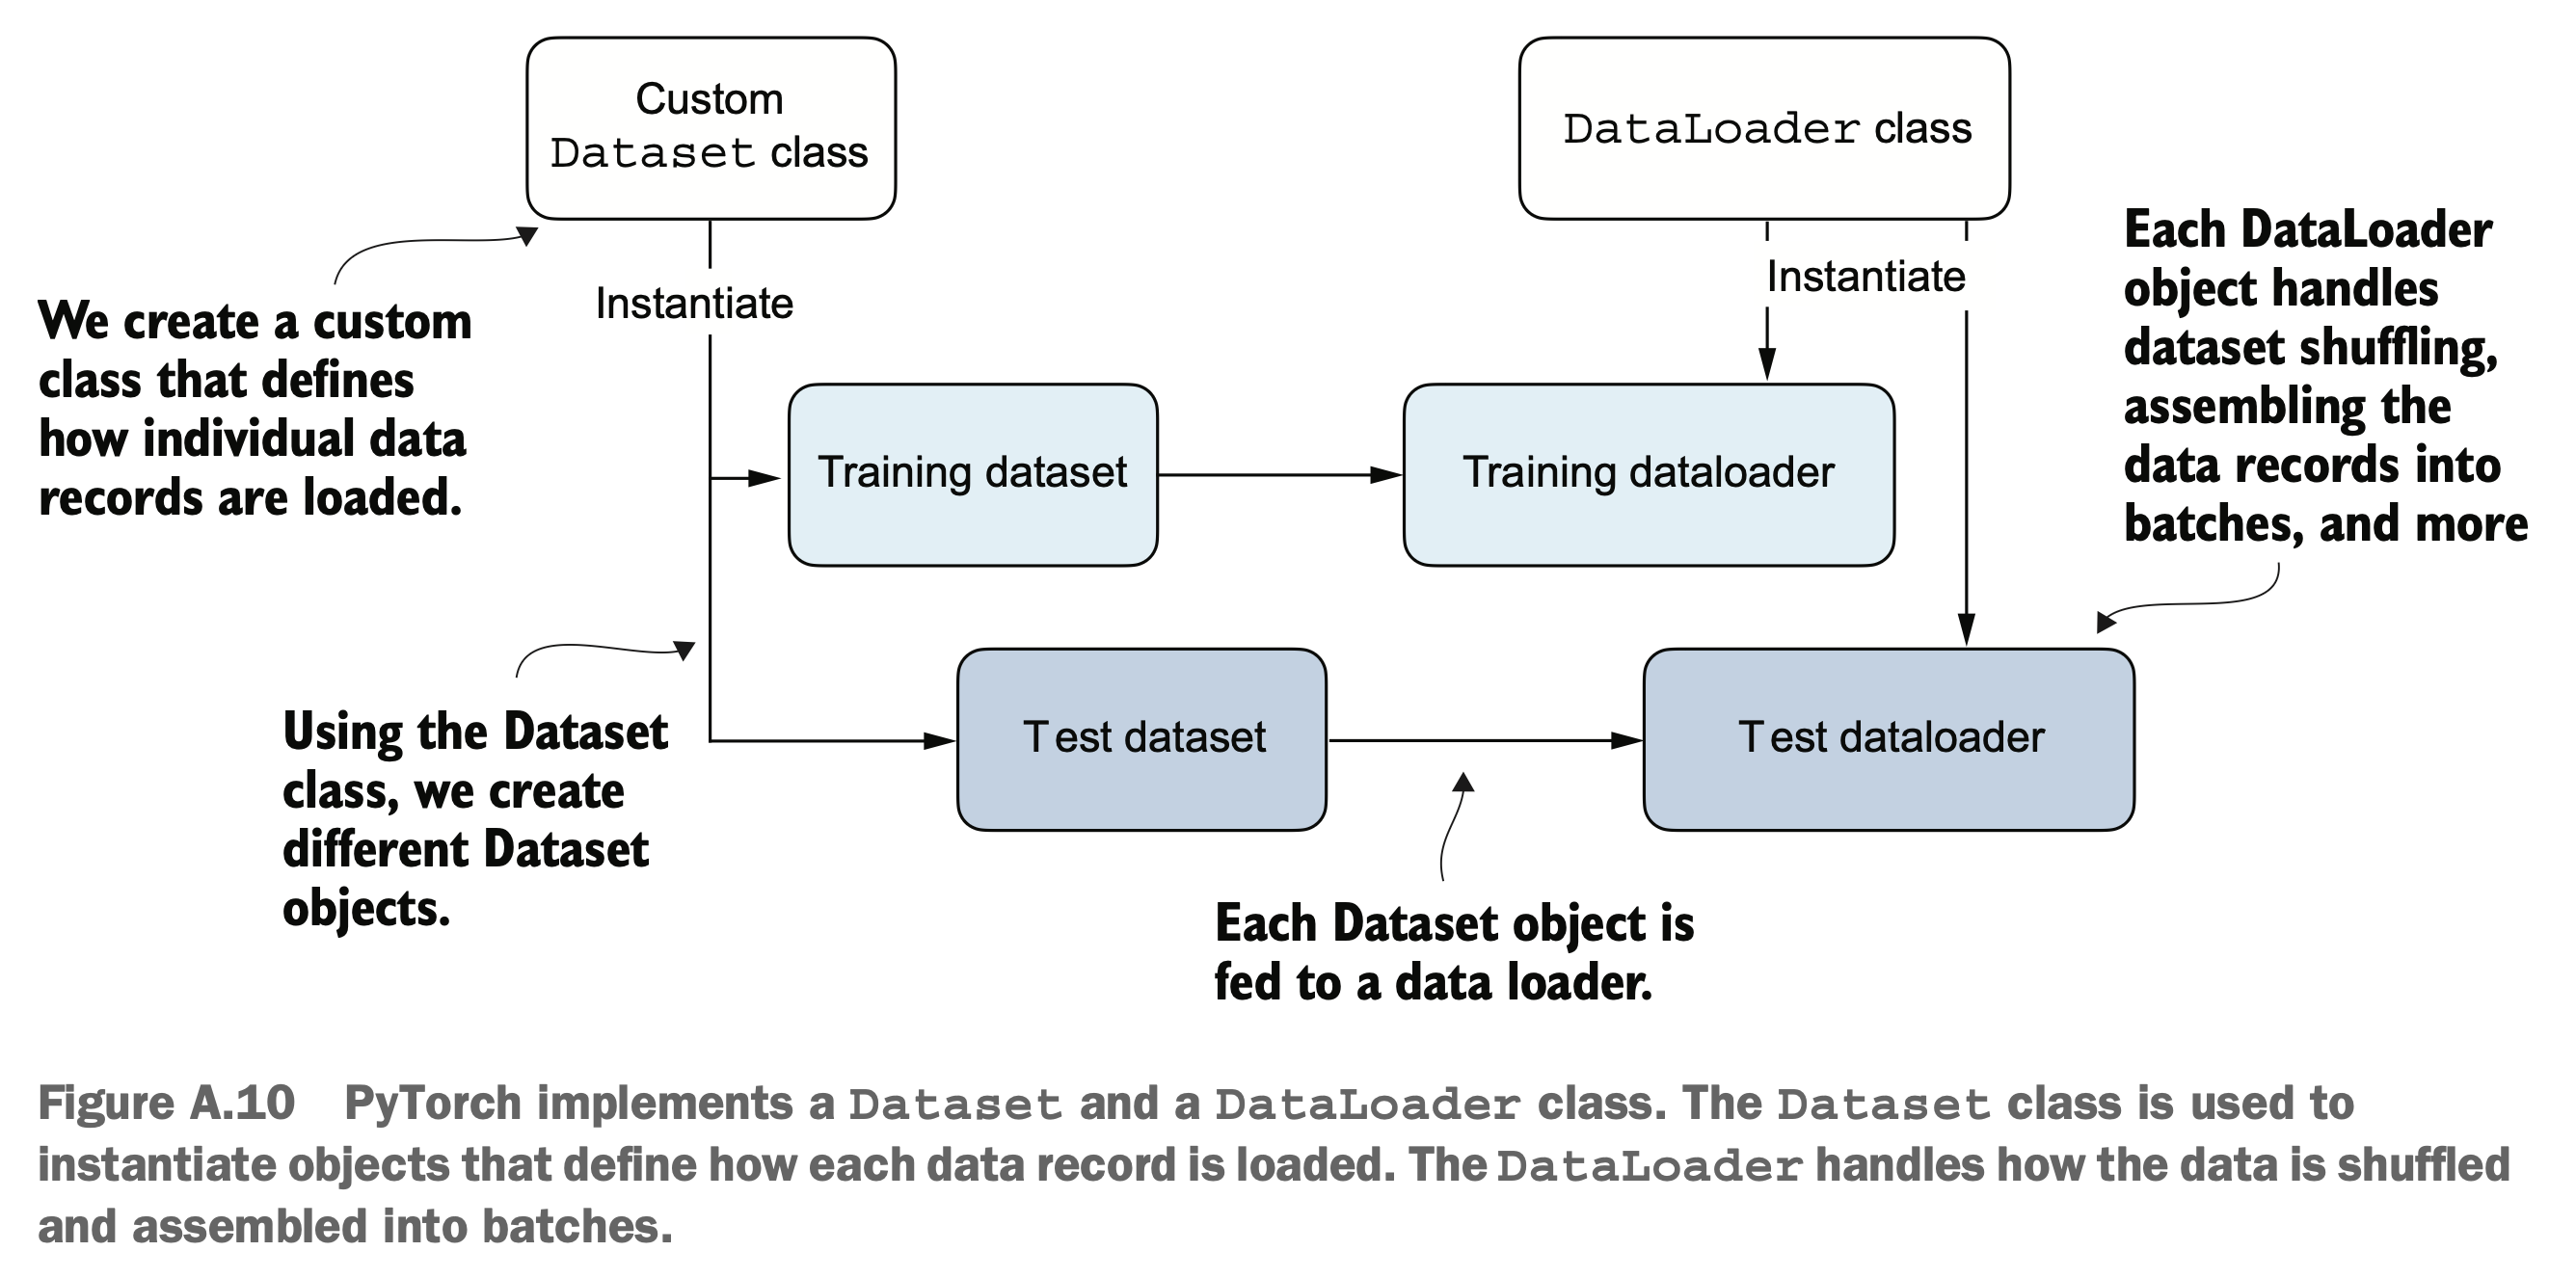